# Diagnóstico de ausência nos preditores de chikungunya

Este notebook investiga o padrão de ausência de dados nos preditores usados para prever óbito em casos internados por chikungunya.
Para cada preditor dos três blocos da ficha de notificação, demografia, sintomas e comorbidades, calcula a taxa de ausência geral, por ano, e estratificada pelo desfecho `obito`.
Também avalia se há diferença relevante de completude entre óbitos e não óbitos, o que indicaria possível viés de informação relacionado ao desfecho, e resume quantos preditores em média estão preenchidos por ficha.
Os dados de entrada já foram tratados pelo pipeline do projeto e são lidos diretamente de `data/processed/chik_treated.parquet`, sem reaplicar nenhuma etapa de limpeza aqui.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
RESULTS_DIR = PROJECT_ROOT / "analysis" / "results_diagnostico"
PLOTS_DIR = PROJECT_ROOT / "analysis" / "plots" / "diagnostico"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

Carrega o dataset tratado produzido pelo pipeline do projeto e organiza os 28 preditores nos três blocos definidos pela ficha de notificação do SINAN.
O bloco de demografia inclui sexo, gestação, raça, escolaridade, unidade federativa, idade em anos e semana epidemiológica de início dos sintomas.
O bloco de sintomas inclui os 14 sinais e sintomas registrados na notificação.
O bloco de comorbidades inclui as 7 condições pré existentes registradas na notificação.

In [2]:
df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "chik_treated.parquet")

BLOCO_DEMOGRAFIA = [
    "CS_SEXO",
    "CS_GESTANT",
    "CS_RACA",
    "CS_ESCOL_N",
    "SG_UF",
    "IDADE_ANOS",
    "SEMANA_EPI_SIN_PRI",
]
BLOCO_SINTOMAS = [
    "FEBRE",
    "MIALGIA",
    "CEFALEIA",
    "EXANTEMA",
    "VOMITO",
    "NAUSEA",
    "DOR_COSTAS",
    "CONJUNTVIT",
    "ARTRITE",
    "ARTRALGIA",
    "PETEQUIA_N",
    "LEUCOPENIA",
    "LACO",
    "DOR_RETRO",
]
BLOCO_COMORBIDADES = [
    "DIABETES",
    "HEMATOLOG",
    "HEPATOPAT",
    "RENAL",
    "HIPERTENSA",
    "ACIDO_PEPT",
    "AUTO_IMUNE",
]

BLOCO_POR_PREDITOR = {}
for coluna in BLOCO_DEMOGRAFIA:
    BLOCO_POR_PREDITOR[coluna] = "demografia"
for coluna in BLOCO_SINTOMAS:
    BLOCO_POR_PREDITOR[coluna] = "sintomas"
for coluna in BLOCO_COMORBIDADES:
    BLOCO_POR_PREDITOR[coluna] = "comorbidades"

PREDITORES = BLOCO_DEMOGRAFIA + BLOCO_SINTOMAS + BLOCO_COMORBIDADES
len(PREDITORES)

28

Calcula a taxa de ausência geral de cada preditor, ou seja, a fração de registros em que o campo não foi preenchido na ficha de notificação.
O resultado é ordenado da maior para a menor taxa de ausência, salvo em `analysis/results_diagnostico/taxa_ausencia_geral_por_preditor.csv`, e representado em um gráfico de barras horizontais em `analysis/plots/diagnostico/taxa_ausencia_geral_por_preditor.png`.

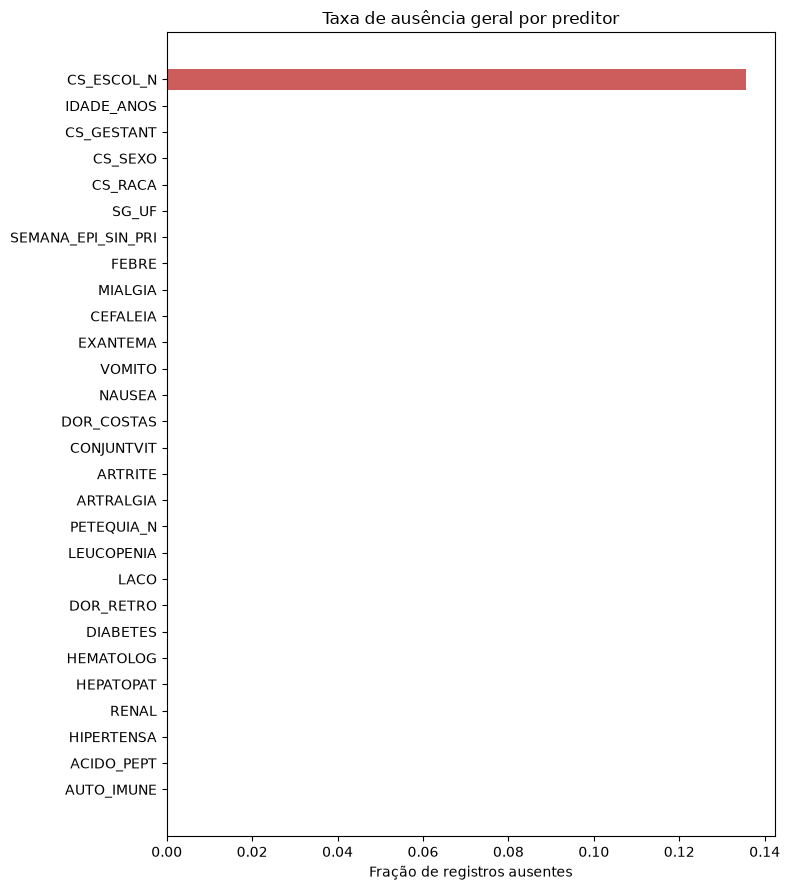

,fracao_ausente,bloco
CS_ESCOL_N,0.135580,demografia
IDADE_ANOS,0.000208,demografia
CS_GESTANT,0.000069,demografia
CS_SEXO,0.000000,demografia
CS_RACA,0.000000,demografia
SG_UF,0.000000,demografia
SEMANA_EPI_SIN_PRI,0.000000,demografia
FEBRE,0.000000,sintomas
MIALGIA,0.000000,sintomas
CEFALEIA,0.000000,sintomas


In [3]:
taxa_ausencia_geral = (
    df[PREDITORES]
    .isna()
    .mean()
    .rename("fracao_ausente")
    .to_frame()
    .assign(bloco=lambda tabela: [BLOCO_POR_PREDITOR[preditor] for preditor in tabela.index])
    .sort_values("fracao_ausente", ascending=False)
)
taxa_ausencia_geral.to_csv(RESULTS_DIR / "taxa_ausencia_geral_por_preditor.csv")

figura, eixo = plt.subplots(figsize=(8, 9))
eixo.barh(taxa_ausencia_geral.index, taxa_ausencia_geral["fracao_ausente"], color="indianred")
eixo.invert_yaxis()
eixo.set_xlabel("Fração de registros ausentes")
eixo.set_title("Taxa de ausência geral por preditor")
figura.tight_layout()
figura.savefig(PLOTS_DIR / "taxa_ausencia_geral_por_preditor.png", dpi=150)
plt.show()

taxa_ausencia_geral

Calcula a taxa de ausência de cada preditor por ano de notificação, para verificar se o padrão de preenchimento mudou entre 2020 e 2025.
O resultado completo é salvo em `analysis/results_diagnostico/taxa_ausencia_por_ano.csv`.
O gráfico de linhas em `analysis/plots/diagnostico/taxa_ausencia_por_ano.png` mostra apenas os preditores que têm pelo menos um registro ausente em algum ano, já que a maioria dos preditores não tem nenhuma ausência.

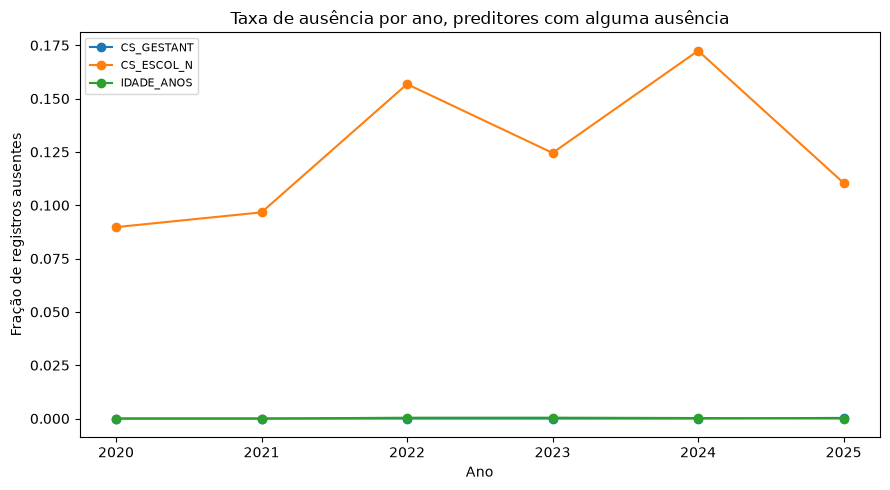

,CS_GESTANT,CS_ESCOL_N,IDADE_ANOS
year,,,
2020,0.000000,0.089744,0.000000
2021,0.000000,0.096672,0.000000
2022,0.000000,0.156793,0.000395
2023,0.000000,0.124539,0.000410
2024,0.000000,0.172448,0.000251
2025,0.000309,0.110460,0.000000


In [4]:
taxa_ausencia_por_ano = df.groupby("year")[PREDITORES].apply(lambda bloco: bloco.isna().mean())
taxa_ausencia_por_ano.to_csv(RESULTS_DIR / "taxa_ausencia_por_ano.csv")

preditores_com_ausencia = taxa_ausencia_por_ano.columns[(taxa_ausencia_por_ano > 0).any(axis=0)]

figura, eixo = plt.subplots(figsize=(9, 5))
for preditor in preditores_com_ausencia:
    eixo.plot(taxa_ausencia_por_ano.index, taxa_ausencia_por_ano[preditor], marker="o", label=preditor)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Fração de registros ausentes")
eixo.set_title("Taxa de ausência por ano, preditores com alguma ausência")
eixo.legend(loc="upper left", fontsize=8)
figura.tight_layout()
figura.savefig(PLOTS_DIR / "taxa_ausencia_por_ano.png", dpi=150)
plt.show()

taxa_ausencia_por_ano[preditores_com_ausencia]

Calcula a taxa de ausência de cada preditor separadamente para os registros com `obito` igual a 0 e com `obito` igual a 1, e a diferença entre os dois grupos.
Uma diferença de completude relevante entre óbitos e não óbitos indicaria possível viés de informação relacionado ao desfecho, por exemplo, se fichas de casos graves fossem preenchidas de forma mais ou menos completa.
Aqui se adota como relevante qualquer diferença absoluta de completude igual ou superior a 1 ponto percentual entre os dois grupos.
O resultado é salvo em `analysis/results_diagnostico/taxa_ausencia_por_obito.csv`.

In [5]:
taxa_ausencia_nao_obito = df.loc[df["obito"] == 0, PREDITORES].isna().mean()
taxa_ausencia_obito = df.loc[df["obito"] == 1, PREDITORES].isna().mean()

taxa_ausencia_por_obito = pd.DataFrame(
    {
        "fracao_ausente_nao_obito": taxa_ausencia_nao_obito,
        "fracao_ausente_obito": taxa_ausencia_obito,
    }
)
taxa_ausencia_por_obito["diferenca_absoluta"] = (
    taxa_ausencia_por_obito["fracao_ausente_obito"] - taxa_ausencia_por_obito["fracao_ausente_nao_obito"]
)
taxa_ausencia_por_obito["bloco"] = [BLOCO_POR_PREDITOR[preditor] for preditor in taxa_ausencia_por_obito.index]
taxa_ausencia_por_obito["diferenca_relevante"] = taxa_ausencia_por_obito["diferenca_absoluta"].abs() >= 0.01
taxa_ausencia_por_obito = taxa_ausencia_por_obito.sort_values("diferenca_absoluta", key=abs, ascending=False)
taxa_ausencia_por_obito.to_csv(RESULTS_DIR / "taxa_ausencia_por_obito.csv")

taxa_ausencia_por_obito

,fracao_ausente_nao_obito,fracao_ausente_obito,diferenca_absoluta,bloco,diferenca_relevante
CS_ESCOL_N,0.135640,0.133981,-0.001659,demografia,False
IDADE_ANOS,0.000216,0.000000,-0.000216,demografia,False
CS_GESTANT,0.000072,0.000000,-0.000072,demografia,False
CS_SEXO,0.000000,0.000000,0.000000,demografia,False
CS_RACA,0.000000,0.000000,0.000000,demografia,False
SG_UF,0.000000,0.000000,0.000000,demografia,False
SEMANA_EPI_SIN_PRI,0.000000,0.000000,0.000000,demografia,False
FEBRE,0.000000,0.000000,0.000000,sintomas,False
MIALGIA,0.000000,0.000000,0.000000,sintomas,False
CEFALEIA,0.000000,0.000000,0.000000,sintomas,False


Calcula, para cada ficha, o número de preditores preenchidos entre os 28 preditores dos três blocos, e resume a distribuição desse número.
Essa distribuição mostra o quão completas são as fichas de notificação na prática, além da taxa de ausência campo a campo.
O resumo é salvo em `analysis/results_diagnostico/distribuicao_num_preditores_preenchidos.csv` e o histograma em `analysis/plots/diagnostico/histograma_num_preditores_preenchidos.png`.

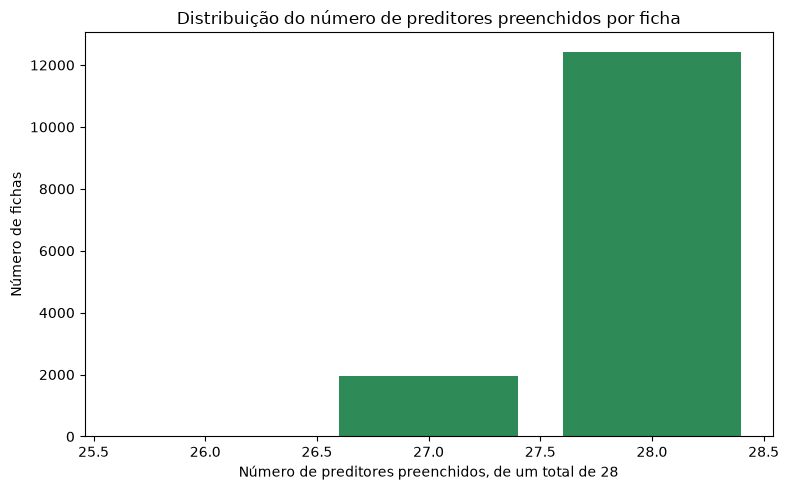

,num_preditores_preenchidos
count,14390.000000
mean,27.864142
std,0.342853
min,26.000000
25%,28.000000
50%,28.000000
75%,28.000000
max,28.000000


In [6]:
num_preditores_preenchidos = df[PREDITORES].notna().sum(axis=1)

resumo_num_preenchidos = num_preditores_preenchidos.describe().to_frame(name="num_preditores_preenchidos")
resumo_num_preenchidos.to_csv(RESULTS_DIR / "distribuicao_num_preditores_preenchidos.csv")

contagem_por_valor = num_preditores_preenchidos.value_counts().sort_index()

figura, eixo = plt.subplots(figsize=(8, 5))
eixo.bar(contagem_por_valor.index, contagem_por_valor.values, color="seagreen")
eixo.set_xlabel(f"Número de preditores preenchidos, de um total de {len(PREDITORES)}")
eixo.set_ylabel("Número de fichas")
eixo.set_title("Distribuição do número de preditores preenchidos por ficha")
figura.tight_layout()
figura.savefig(PLOTS_DIR / "histograma_num_preditores_preenchidos.png", dpi=150)
plt.show()

resumo_num_preenchidos

## Síntese dos achados

Entre os 28 preditores analisados, apenas três têm algum registro ausente, `CS_ESCOL_N`, `IDADE_ANOS` e `CS_GESTANT`.
Os outros 25 preditores, incluindo todos os 14 sintomas e todas as 7 comorbidades, estão preenchidos em 100 por cento dos 14390 registros.
`CS_ESCOL_N`, escolaridade, é o preditor com maior ausência, cerca de 13,6 por cento dos registros, um nível de ausência consideravelmente maior que o dos demais campos de demografia.
`IDADE_ANOS` e `CS_GESTANT` têm ausência residual, abaixo de 0,03 por cento dos registros.

A taxa de ausência por ano desses três preditores se mantém próxima da taxa geral em todos os anos de 2020 a 2025, sem tendência clara de piora ou melhora ao longo do tempo.

Comparando registros com `obito` igual a 0 e igual a 1, nenhum preditor apresentou diferença de completude igual ou superior a 1 ponto percentual entre os dois grupos.
A maior diferença observada foi em `CS_ESCOL_N`, com ausência de 13,6 por cento entre não óbitos e 13,4 por cento entre óbitos, uma diferença de cerca de 0,17 ponto percentual, portanto não relevante pelo critério adotado.
Isso indica que não há evidência de viés de informação relacionado ao desfecho nos preditores deste dataset, ou seja, o preenchimento das fichas não parece depender de o caso ter evoluído para óbito.

O número de preditores preenchidos por ficha, de um total de 28, tem mediana e terceiro quartil iguais a 28, com média de aproximadamente 27,9 e mínimo de 26.
Ou seja, a grande maioria das fichas está praticamente completa nos 28 preditores considerados, e a ausência de dados neste dataset está concentrada quase inteiramente no campo de escolaridade.